In [42]:
from google.colab import files
uploaded = files.upload()

Saving nasabah_raw.csv to nasabah_raw (3).csv


In [43]:
from google.colab import files
uploaded = files.upload()

Saving data_kredit_eksternal.csv to data_kredit_eksternal (2).csv


In [44]:
# SETUP

In [45]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def file_terbaru(pola):
    return max(glob.glob(pola), key=os.path.getmtime)

PATH_RAW = file_terbaru("nasabah_raw*.csv")
PATH_EXT = file_terbaru("data_kredit_eksternal*.csv")
PATH_OUT = "clean_nasabah_final.csv"
print("Membaca:", PATH_RAW, "|", PATH_EXT)

KEY = "ID_Pelanggan"
TARGET = "Status_Default"
COLS_MEDIAN = ["Usia", "Pendapatan_Bulanan", "Lama_Bekerja_Thn"]
COL_DISKRIT = "Jumlah_Kartu_Kredit"
COLS_KATEGORI = ["Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain"]
USIA_MIN, USIA_MAX = 17, 100

Membaca: nasabah_raw (3).csv | data_kredit_eksternal (2).csv


In [46]:
# A. PEMERIKSAAN AWAL & PENGHAPUSAN DUPLIKAT

In [47]:
def load_data(path):
    return pd.read_csv(path)

def inspect_data(df):
    print("Dimensi (baris, kolom):", df.shape)
    print()
    df.info()

def remove_duplicates(df):
    n_dup = df.duplicated().sum()
    print("Jumlah duplikat penuh:", n_dup)
    if n_dup:
        print("Sampel baris terduplikasi:")
        display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))
    df = df.drop_duplicates().reset_index(drop=True)
    print("Sisa baris setelah penghapusan duplikat:", len(df))
    return df

df_raw = load_data(PATH_RAW)
inspect_data(df_raw)
df = remove_duplicates(df_raw)

Dimensi (baris, kolom): (1045, 9)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB
Jumlah duplikat penuh: 45
Sampel baris terduplikasi:


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est
59,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
1039,CUST-1060,53.0,14765000.0,461.0,3.0,Single,SMA,0,177180000.0
76,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
1011,CUST-1077,34.0,6920000.0,510.0,22.0,Single,SMA,1,83040000.0
96,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
1041,CUST-1097,27.0,12499000.0,578.0,4.0,Single,Sarjana,0,149988000.0
101,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
1026,CUST-1102,43.0,7972000.0,365.0,6.0,Single,Magister,1,95664000.0
136,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN
1009,CUST-1137,-5.0,NaN,580.0,11.0,Cerai,Sarjana,1,NaN


Sisa baris setelah penghapusan duplikat: 1000


In [48]:
# B. PENANGANAN KESALAHAN DATA

In [49]:
def clean_text_column(s):
    return s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.title()

print("Nilai unik Status_Pernikahan SEBELUM:", df["Status_Pernikahan"].unique())
df["Status_Pernikahan"] = clean_text_column(df["Status_Pernikahan"])
print("Nilai unik Status_Pernikahan SESUDAH:", df["Status_Pernikahan"].unique())

def fix_usia(df, lo=USIA_MIN, hi=USIA_MAX):
    df = df.copy()
    df["Usia"] = pd.to_numeric(df["Usia"], errors="coerce")
    invalid = ~df["Usia"].between(lo, hi) & df["Usia"].notna()
    print(f"Usia tidak wajar (di luar {lo}-{hi}) -> NaN: {invalid.sum()} baris")
    df.loc[invalid, "Usia"] = np.nan
    return df

df = fix_usia(df)

Nilai unik Status_Pernikahan SEBELUM: ['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']
Nilai unik Status_Pernikahan SESUDAH: <StringArray>
['Menikah', 'Single', 'Cerai']
Length: 3, dtype: string
Usia tidak wajar (di luar 17-100) -> NaN: 35 baris


In [50]:
# C. INTEGRASI DATA (LEFT JOIN)

In [51]:
df_ext = load_data(PATH_EXT)
print("Dimensi data eksternal:", df_ext.shape)

if df_ext[KEY].duplicated().any():
    print("Peringatan: kunci duplikat di data eksternal, diambil record pertama.")
    df_ext = df_ext.drop_duplicates(subset=KEY, keep="first")

n_before = len(df)
df_merged = df.merge(df_ext, on=KEY, how="left")
print("Dimensi sebelum merge:", (n_before, df.shape[1]))
print("Dimensi setelah merge:", df_merged.shape)
assert len(df_merged) == n_before, "Jumlah baris berubah setelah left join!"

Dimensi data eksternal: (850, 3)
Dimensi sebelum merge: (1000, 9)
Dimensi setelah merge: (1000, 11)


In [52]:
# D. MISSING VALUES

In [53]:
tabel = pd.DataFrame({
    "Jumlah": df_merged.isna().sum(),
    "Persen (%)": (df_merged.isna().mean() * 100).round(2)
}).sort_values("Persen (%)", ascending=False)
display(tabel)

df_imputed = df_merged.copy()
for c in COLS_KATEGORI:
    df_imputed[c] = clean_text_column(df_imputed[c])

for c in COLS_MEDIAN:
    df_imputed[c] = df_imputed[c].fillna(df_imputed[c].median())
df_imputed[COL_DISKRIT] = df_imputed[COL_DISKRIT].fillna(0)

for c in df_imputed.columns:
    if c != TARGET and df_imputed[c].isna().any():
        if pd.api.types.is_numeric_dtype(df_imputed[c]):
            df_imputed[c] = df_imputed[c].fillna(df_imputed[c].median())
        else:
            df_imputed[c] = df_imputed[c].fillna(df_imputed[c].mode()[0])

df_imputed = df_imputed.dropna(subset=[TARGET]).reset_index(drop=True)

display(pd.DataFrame({"Missing tersisa": df_imputed.isna().sum()}))
assert df_imputed.isna().sum().sum() == 0

,Jumlah,Persen (%)
Pernah_Gagal_Bayar_Lain,150,15.0
Jumlah_Kartu_Kredit,150,15.0
Pendapatan_Bulanan,60,6.0
Pendapatan_Tahunan_Est,60,6.0
Lama_Bekerja_Thn,40,4.0
Tingkat_Pendidikan,35,3.5
Usia,35,3.5
ID_Pelanggan,0,0.0
Skor_Kredit,0,0.0
Status_Pernikahan,0,0.0


,Missing tersisa
ID_Pelanggan,0
Usia,0
Pendapatan_Bulanan,0
Skor_Kredit,0
Lama_Bekerja_Thn,0
Status_Pernikahan,0
Tingkat_Pendidikan,0
Status_Default,0
Pendapatan_Tahunan_Est,0
Pernah_Gagal_Bayar_Lain,0


In [54]:
# E. PENANGANAN OUTLIER (Pendapatan_Bulanan)

Q1=10,192,000.00  Q3=14,100,250.00  IQR=3,908,250.00
Batas bawah=4,329,625.00  Batas atas=19,962,625.00  Jumlah outlier=22


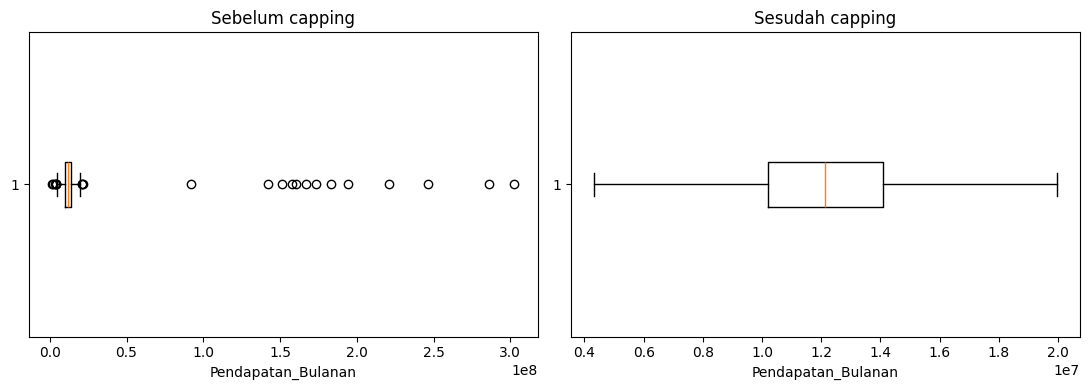

Jumlah baris setelah capping: 1000


In [55]:
df_clean = df_imputed.copy()      # selalu mulai dari data hasil sel D
col = "Pendapatan_Bulanan"

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot(df_clean[col], vert=False)
ax[0].set_title("Sebelum capping")
ax[0].set_xlabel(col)

Q1, Q3 = df_clean[col].quantile([0.25, 0.75])
IQR = Q3 - Q1
batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR
n_out = ((df_clean[col] < batas_bawah) | (df_clean[col] > batas_atas)).sum()
print(f"Q1={Q1:,.2f}  Q3={Q3:,.2f}  IQR={IQR:,.2f}")
print(f"Batas bawah={batas_bawah:,.2f}  Batas atas={batas_atas:,.2f}  Jumlah outlier={n_out}")

df_clean[col] = df_clean[col].clip(lower=batas_bawah, upper=batas_atas)
df_clean["Pendapatan_Tahunan_Est"] = df_clean["Pendapatan_Bulanan"] * 12

ax[1].boxplot(df_clean[col], vert=False)
ax[1].set_title("Sesudah capping")
ax[1].set_xlabel(col)
plt.tight_layout()
plt.show()
print("Jumlah baris setelah capping:", len(df_clean))

In [56]:
# F. CATEGORICAL ENCODING

In [57]:
def encode_features(df):
    df = df.copy()

    map_pendidikan = {"Sma": 1, "Sarjana": 2, "Magister": 3}
    df["Pendidikan_Ord"] = df["Tingkat_Pendidikan"].map(map_pendidikan)

    map_biner = {"Ya": 1, "Tidak": 0}
    df["Gagal_Bayar_Lain_Bin"] = df["Pernah_Gagal_Bayar_Lain"].map(map_biner)

    for c in ["Pendidikan_Ord", "Gagal_Bayar_Lain_Bin"]:
        assert df[c].notna().all(), f"Ada kategori tak terpetakan pada {c}"

    df = pd.get_dummies(df, columns=["Status_Pernikahan"], drop_first=True, dtype=int)
    return df.drop(columns=["Tingkat_Pendidikan", "Pernah_Gagal_Bayar_Lain", KEY])

df_enc = encode_features(df_clean)
display(df_enc.head())
df_enc.info()

,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Default,Pendapatan_Tahunan_Est,Jumlah_Kartu_Kredit,Pendidikan_Ord,Gagal_Bayar_Lain_Bin,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,0,121416000.0,5.0,3,0,1,0
1,48.0,10514000.0,331.0,20.0,0,126168000.0,3.0,2,0,1,0
2,34.0,13257000.0,690.0,22.0,0,159084000.0,5.0,3,0,1,0
3,27.0,10832000.0,576.0,7.0,0,129984000.0,6.0,2,1,1,0
4,41.0,8295000.0,831.0,15.0,0,99540000.0,4.0,1,1,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Usia                       1000 non-null   float64
 1   Pendapatan_Bulanan         1000 non-null   float64
 2   Skor_Kredit                1000 non-null   float64
 3   Lama_Bekerja_Thn           1000 non-null   float64
 4   Status_Default             1000 non-null   int64  
 5   Pendapatan_Tahunan_Est     1000 non-null   float64
 6   Jumlah_Kartu_Kredit        1000 non-null   float64
 7   Pendidikan_Ord             1000 non-null   int64  
 8   Gagal_Bayar_Lain_Bin       1000 non-null   int64  
 9   Status_Pernikahan_Menikah  1000 non-null   int64  
 10  Status_Pernikahan_Single   1000 non-null   int64  
dtypes: float64(6), int64(5)
memory usage: 86.1 KB


In [58]:
# G. FEATURE SCALING (Z-SCORE)

In [59]:
X = df_enc.drop(columns=[TARGET])
y = df_enc[TARGET]

num_cols = [c for c in X.columns if X[c].nunique() > 2]
print("Kolom yang distandardisasi:", num_cols)

sample_cols = ["Usia", "Pendapatan_Bulanan", "Lama_Bekerja_Thn"]

print("\n=== describe() SEBELUM standardisasi ===")
display(X[sample_cols].describe().round(3))

X_scaled = X.copy()
X_scaled[num_cols] = (X[num_cols] - X[num_cols].mean()) / X[num_cols].std(ddof=0)

print("=== describe() SESUDAH standardisasi ===")
display(X_scaled[sample_cols].describe().round(3))

Kolom yang distandardisasi: ['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Pendapatan_Tahunan_Est', 'Jumlah_Kartu_Kredit', 'Pendidikan_Ord']

=== describe() SEBELUM standardisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.000,1.000000e+03,1000.000
mean,40.082,1.212750e+07,12.948
std,11.580,3.062611e+06,6.690
min,20.000,4.329625e+06,1.000
25%,30.000,1.019200e+07,8.000
50%,41.000,1.213200e+07,13.000
75%,50.000,1.410025e+07,19.000
max,59.000,1.996262e+07,24.000


=== describe() SESUDAH standardisasi ===


,Usia,Pendapatan_Bulanan,Lama_Bekerja_Thn
count,1000.000,1000.000,1000.000
mean,-0.000,-0.000,-0.000
std,1.001,1.001,1.001
min,-1.735,-2.547,-1.787
25%,-0.871,-0.632,-0.740
50%,0.079,0.001,0.008
75%,0.857,0.644,0.905
max,1.634,2.560,1.653


In [60]:
# SIMPAN HASIL AKHIR

In [61]:
final_df = pd.concat([X_scaled, y], axis=1)
final_df.to_csv(PATH_OUT, index=False)
print("Tersimpan:", PATH_OUT, final_df.shape)

Tersimpan: clean_nasabah_final.csv (1000, 11)


A.3: Sisa data setelah hapus duplikat adalah 1000 baris (dari 1045, ada 45 duplikat).
B.3: Usia yang tidak logis, seperti −5, harus dibersihkan lebih dulu karena nilai salah input menggeser mean dan median. Imputasi yang dihitung dari data kotor akan menyebarkan kesalahan itu ke semua baris yang kosong.
D: Median dipakai untuk numerik karena tahan terhadap outlier. Kartu kredit diisi 0 karena kosong dianggap tidak punya kartu. Kategorikal diisi modus agar distribusi kategori tidak berubah drastis.
E.4: Membuang baris outlier menghilangkan informasi nasabah, termasuk kolom lain yang sebenarnya valid, dan mengecilkan data. Pendapatan tinggi bisa jadi nasabah asli, bukan kesalahan. Jika outlier berkaitan dengan Status_Default, membuangnya juga mengubah proporsi kelas target dan menimbulkan bias. Capping mempertahankan semua baris.
G: Setelah Z-score, semua fitur berskala sama, sehingga Pendapatan (jutaan) tidak mendominasi Usia (puluhan).